# 17 · Adaptive priority experiments

## Purpose

Measure how expected and observed prioritization metrics change across review capacity and cost assumptions.

## Method

Run sensitivity analysis over 5%, 10%, 20%, and 30% capacities and three explicitly hypothetical cost profiles, retaining strategy-level precision, recall, and false-negative cost.

## Interpretation

Use the displayed tables, figures, and saved metrics produced by this run. Do not fill this section with assumed outcomes. For every result, distinguish observed evidence from interpretation.

## Limitations

Capacity rankings are evaluated on one decision-study holdout. They require replication across folds before a stability claim.

## References

The cost simulator and metrics are implemented in returnwise.decision.


In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd().resolve()
while not (ROOT / 'returnwise').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from IPython.display import display
from returnwise.research_state import load_state, save_state
state = load_state()
print('Project:', ROOT)
print('Notebook:', '17 · Adaptive priority experiments')


Project: C:\Users\Lenovo\Documents\Who is back
Notebook: 17 · Adaptive priority experiments


,strategy,capacity_percent,capacity_rows,review_count,false_positive_cost_assumption,false_negative_cost_assumption,review_cost_assumption,expected_decision_cost,false_positives,false_negatives,return_cases_identified,precision_at_k,recall_at_k,count_type,roc_auc,pr_auc,brier_score,log_loss,false_negative_cost_scenario,review_cost_scenario
0,random,5.0,1600,1600,1.0,2.0,0.1,29893.0,853,14440,747,0.466875,0.049187,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,2.0,0.1
1,probability_only,5.0,1600,1600,1.0,2.0,0.1,28933.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,2.0,0.1
2,fixed_threshold,5.0,1600,1600,1.0,2.0,0.1,28933.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,2.0,0.1
3,cost_sensitive,5.0,1600,1600,1.0,2.0,0.1,28933.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,2.0,0.1
4,calibration_aware_cost_sensitive,5.0,1600,1600,1.0,2.0,0.1,28933.0,533,14120,1067,0.666875,0.070257,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313,2.0,0.1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
211,probability_only,30.0,9600,9600,1.0,10.0,0.5,106617.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,10.0,0.5
212,fixed_threshold,30.0,9600,9600,1.0,10.0,0.5,106617.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,10.0,0.5
213,cost_sensitive,30.0,9600,9600,1.0,10.0,0.5,106617.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.243004,0.678976,10.0,0.5
214,calibration_aware_cost_sensitive,30.0,9600,9600,1.0,10.0,0.5,106617.0,4177,9764,5423,0.564896,0.357082,observed on labeled validation data,0.592534,0.557368,0.242690,0.678313,10.0,0.5


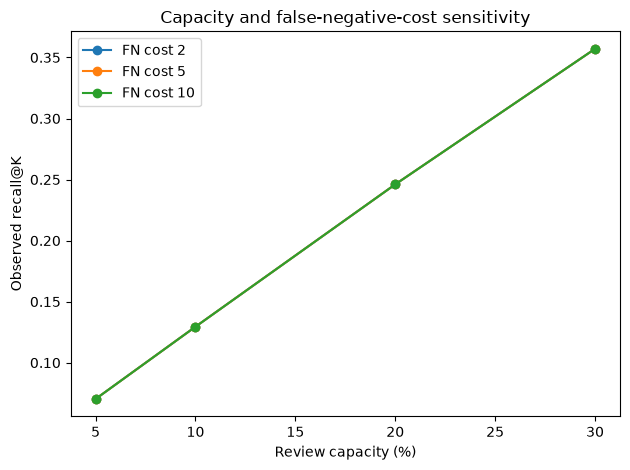

In [2]:
from returnwise.decision import evaluate_review_strategies
from returnwise.research_state import load_state, save_state
import matplotlib.pyplot as plt
import pandas as pd

state = load_state()
predictions = state['decision_predictions']
calibrator = state['decision_calibrator_name']
raw = predictions['probability_uncalibrated'].to_numpy()
calibrated = predictions[f'probability_{calibrator}'].to_numpy()
y = predictions['y_true'].to_numpy()
rows = []
for fn_cost in [2.0, 5.0, 10.0]:
    for review_cost in [0.1, 0.25, 0.5]:
        costs = {'false_positive': 1.0, 'false_negative': fn_cost, 'review': review_cost}
        part = evaluate_review_strategies(raw, y_true=y, calibrated_probabilities=calibrated, costs=costs)
        part['false_negative_cost_scenario'] = fn_cost
        part['review_cost_scenario'] = review_cost
        rows.append(part)
priority_sensitivity = pd.concat(rows, ignore_index=True)
display(priority_sensitivity)
plot_data = priority_sensitivity[(priority_sensitivity['strategy'] == 'calibration_aware_cost_sensitive') & (priority_sensitivity['review_cost_scenario'] == 0.25)]
for fn_cost, group in plot_data.groupby('false_negative_cost_scenario'):
    plt.plot(group['capacity_percent'], group['recall_at_k'], marker='o', label=f'FN cost {fn_cost:g}')
plt.xlabel('Review capacity (%)')
plt.ylabel('Observed recall@K')
plt.title('Capacity and false-negative-cost sensitivity')
plt.legend()
plt.tight_layout()
plt.show()
state['priority_sensitivity'] = priority_sensitivity
from returnwise.experiments import log_experiment
log_experiment('Adaptive priority sensitivity analysis', None,
               {'results': priority_sensitivity.to_dict(orient='records')},
               {'capacities': [5, 10, 20, 30], 'costs_are_simulated': True})
save_state(state)
